In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_colwidth", None)


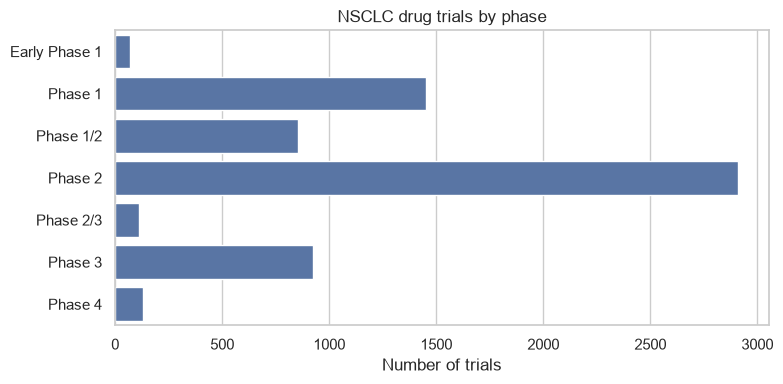

In [ ]:
sns.set_theme(style="whitegrid")
trials = pd.read_csv("../data/processed/nsclc_trials_clean.csv")
order = ["Early Phase 1", "Phase 1", "Phase 1/2", "Phase 2", "Phase 2/3",
"Phase 3", "Phase 4"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=trials, y="phase", order=order, ax=ax)
ax.set(title="NSCLC drug trials by phase", xlabel="Number of trials",
ylabel="")
fig.tight_layout()
fig.savefig("../figures/01_trials_by_phase.png", dpi=150)


Trials shown: 6560
Left out: 39 with no start year, 651 outside 2000–2025
Peak year: 2025 with 462 trials


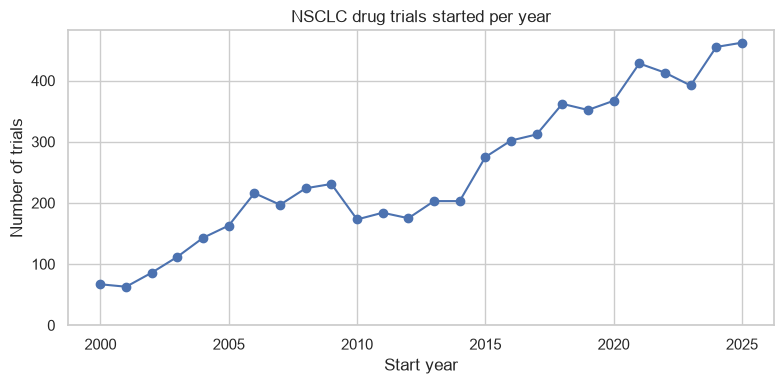

In [5]:
sns.set_theme(style="whitegrid")

# Load the cleaned data and make start_year whole numbers again
trials = pd.read_csv("../data/processed/nsclc_trials_clean.csv")
trials["start_year"] = trials["start_year"].astype("Int64")

# Count trials per start year (trials with no start year are left out automatically)
per_year = trials.groupby("start_year").size()

# Keep 2000–2025: earlier years are undercounted, 2026 is incomplete,
# and later years are planned starts that haven't happened yet
FIRST_YEAR, LAST_YEAR = 2000, 2025
shown = per_year.loc[FIRST_YEAR:LAST_YEAR]
shown.index = shown.index.astype(int)

# Report what the chart leaves out
missing_year = trials["start_year"].isna().sum()
outside = per_year.sum() - shown.sum()
print(f"Trials shown: {shown.sum()}")
print(f"Left out: {missing_year} with no start year, {outside} outside {FIRST_YEAR}–{LAST_YEAR}")
print(f"Peak year: {shown.idxmax()} with {shown.max()} trials")

# Draw and save the line chart
fig, ax = plt.subplots(figsize=(8, 4))
shown.plot(ax=ax, marker="o")
ax.set(title="NSCLC drug trials started per year",
       xlabel="Start year", ylabel="Number of trials")
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig("../figures/02_trials_per_year.png", dpi=150)

sponsor_type   Industry  Academic or hospital  NIH  Other government  Other
phase                                                                      
Early Phase 1      17.6                  76.5  1.5               4.4    0.0
Phase 1            62.4                  31.6  4.3               0.6    1.1
Phase 1/2          63.6                  31.5  2.5               1.3    1.2
Phase 2            30.4                  61.7  3.1               1.9    3.0
Phase 2/3          45.0                  45.9  1.8               0.9    6.4
Phase 3            62.5                  29.6  2.5               1.7    3.7
Phase 4            45.8                  48.9  0.0               4.6    0.8


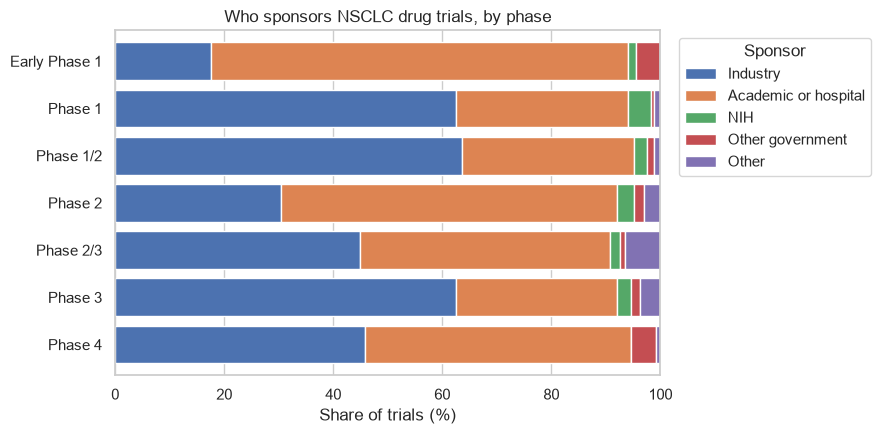

In [ ]:
# Share of each sponsor type within each phase (each row adds up to 100%)
shares = pd.crosstab(trials["phase"], trials["sponsor_type"], normalize="index") * 100

# Put phases in development order and sponsor types in a sensible order
sponsor_order = ["Industry", "Academic or hospital", "NIH", "Other government", "Other"]
shares = shares.reindex(index=order, columns=sponsor_order).fillna(0)

print(shares.round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
shares.plot(kind="barh", stacked=True, ax=ax, width=0.8)
ax.invert_yaxis()
ax.set(title="Who sponsors NSCLC drug trials, by phase",
       xlabel="Share of trials (%)", ylabel="")
ax.set_xlim(0, 100)
ax.legend(title="Sponsor", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig("../figures/03_sponsor_by_phase.png", dpi=150)

,Completed %,Terminated %,Withdrawn %,Stopped early %,Finished trials
Early Phase 1,48.5,33.3,18.2,51.5,33
Phase 1,65.4,29.6,5.0,34.6,980
Phase 1/2,57.6,34.6,7.8,42.4,448
Phase 2,69.2,23.1,7.7,30.8,1596
Phase 2/3,69.2,30.8,0.0,30.8,39
Phase 3,74.3,22.2,3.5,25.7,482
Phase 4,79.7,18.8,1.4,20.3,69


105 of 1026 terminated trials give no reason.

- NCT03367819 (Phase 1/2): The study was stopped after interim analysis indicated that overall result was not sufficient to satisfy per-protocol criteria to move forward in metastatic, castration-resistant prostate cancer (mCRPC) and non-small cell lung cancer (NSCLC) cohorts.
- NCT04543188 (Phase 1): Pfizer has made an internal business decision to not continue further development of PF-07284890. This decision was not due to major safety concerns or requests from any regulatory authorities.
- NCT02460367 (Phase 1): Lack of enrollment and changing landscape of standard of care.
- NCT04504916 (Phase 2): Business reasons
- NCT00692380 (Phase 1): insufficient accrual
- NCT01210378 (Phase 2): Accrual stopped
- NCT00232206 (Phase 2): study terminated due to slow accrual
- NCT04442126 (Phase 1/2): A business decision was made to discontinue further enrollment. There were no safety concerns that contributed to this decision.
- NCT05846646 (Phase 

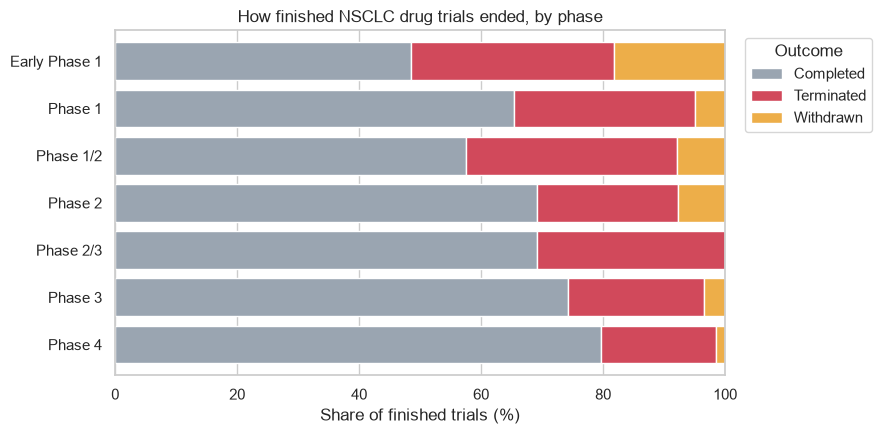

In [ ]:
outcomes = ["COMPLETED", "TERMINATED", "WITHDRAWN"]
finished = trials[trials["status"].isin(outcomes)]

# Counts and row percentages of each outcome within each phase
counts = pd.crosstab(finished["phase"], finished["status"]).reindex(index=order, columns=outcomes).fillna(0)
shares = counts.div(counts.sum(axis=1), axis=0) * 100

# Summary table with readable headers
summary = shares.copy()
summary["stopped_early_%"] = shares["TERMINATED"] + shares["WITHDRAWN"]
summary["n_finished"] = counts.sum(axis=1).astype(int)

nice = summary.round(1).rename(columns={
    "COMPLETED": "Completed %",
    "TERMINATED": "Terminated %",
    "WITHDRAWN": "Withdrawn %",
    "stopped_early_%": "Stopped early %",
    "n_finished": "Finished trials",
})
nice.columns.name = None
nice.index.name = None
display(nice)

# Stacked bar chart, with stopped-early outcomes in warning colors
labels = shares.rename(columns={"COMPLETED": "Completed", "TERMINATED": "Terminated", "WITHDRAWN": "Withdrawn"})
fig, ax = plt.subplots(figsize=(9, 4.5))
labels.plot(kind="barh", stacked=True, ax=ax, width=0.8, color=["#9aa5b1", "#d1495b", "#edae49"])
ax.invert_yaxis()
ax.set(title="How finished NSCLC drug trials ended, by phase",
       xlabel="Share of finished trials (%)", ylabel="")
ax.set_xlim(0, 100)
ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig("../figures/04_outcomes_by_phase.png", dpi=150)

# Why trials were terminated: a random sample of stated reasons
terminated = finished[finished["status"] == "TERMINATED"]
print(f"{terminated['why_stopped'].isna().sum()} of {len(terminated)} terminated trials give no reason.\n")

for _, row in terminated.dropna(subset=["why_stopped"]).sample(10, random_state=1).iterrows():
    print(f"- {row['nct_id']} ({row['phase']}): {row['why_stopped']}")

Dropped 366 drug-phase trials with zero or missing enrollment.



,Trials,25th pct,Median,75th pct,Largest
Early Phase 1,62,10,20,36,146
Phase 1,1366,17,34,81,1756
Phase 1/2,811,31,67,160,1438
Phase 2,2720,30,53,101,6000
Phase 2/3,107,93,210,470,10000
Phase 3,886,210,394,600,53454
Phase 4,129,40,100,170,6586


,nct_id,phase,status,enrollment
3679,NCT00047385,Phase 3,COMPLETED,53454.0
6967,NCT03851445,Phase 2/3,RECRUITING,10000.0
528,NCT00949910,Phase 4,COMPLETED,6586.0


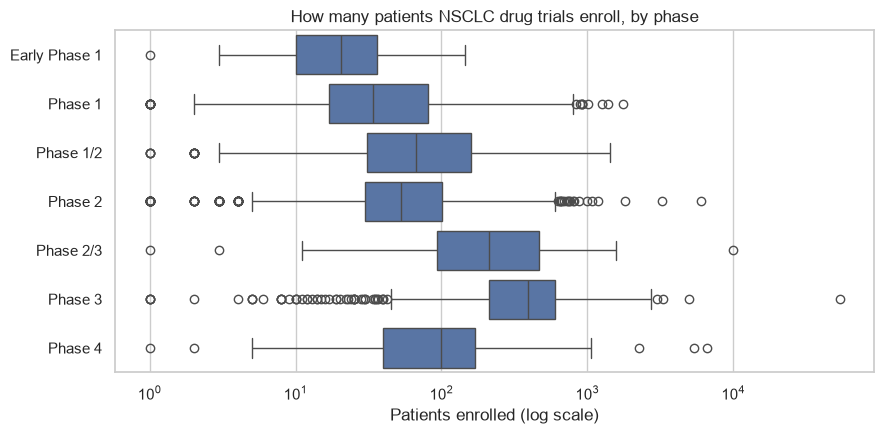

In [ ]:
# Keep trials with a real enrollment number (drops zeros and missing values)
sized = trials[(trials["enrollment"] > 0) & (trials["phase"].isin(order))]
print(f"Dropped {len(trials[trials['phase'].isin(order)]) - len(sized)} drug-phase trials with zero or missing enrollment.\n")

# Summary table for typical sizes of a phase
stats = (sized.groupby("phase")["enrollment"]
              .describe()[["count", "25%", "50%", "75%", "max"]]
              .reindex(order)
              .round(0).astype(int)
              .rename(columns={"count": "Trials", "25%": "25th pct", "50%": "Median",
                               "75%": "75th pct", "max": "Largest"}))
stats.index.name = None
display(stats)

# Checking the trials with highest enrollment. Are these real or data-entry errors? 
display(sized.nlargest(3, "enrollment")[["nct_id", "phase", "status", "enrollment"]])

# Box plot on a log scale
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=sized, x="enrollment", y="phase", order=order, log_scale=True, ax=ax)
ax.set(title="How many patients NSCLC drug trials enroll, by phase",
       xlabel="Patients enrolled (log scale)", ylabel="")
fig.tight_layout()
fig.savefig("../figures/05_enrollment_by_phase.png", dpi=150)

,Results posted %,Completed trials
Industry,48.0,1280
Other,44.6,92
NIH,39.5,114
Academic or hospital,28.8,1216
Other government,0.0,19


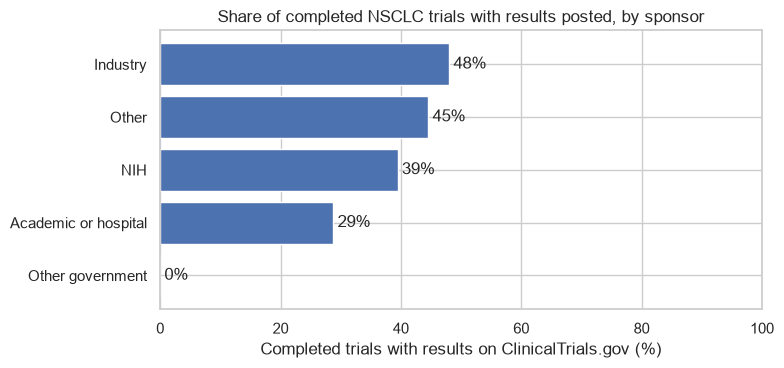

In [23]:
#Do sponsors post their results?
completed = trials[trials["status"] == "COMPLETED"]

# Share with results posted, plus how many completed trials each sponsor type has
posted = (completed.groupby("sponsor_type")["has_results"]
                   .agg(["mean", "size"])
                   .rename(columns={"mean": "share", "size": "n"}))
posted["share"] = posted["share"] * 100
posted = posted.sort_values("share", ascending=False)

table = posted.round(1).rename(columns={"share": "Results posted %", "n": "Completed trials"})
table.index.name = None
display(table)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(posted.index, posted["share"])
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3)
ax.set(title="Share of completed NSCLC trials with results posted, by sponsor",
       xlabel="Completed trials with results on ClinicalTrials.gov (%)", ylabel="")
ax.set_xlim(0, 100)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig("../figures/06_results_posted_by_sponsor.png", dpi=150)

In [ ]:
# Results posting broken down by phase and by era, with counts in every cell

sponsor_order = ["Industry", "Academic or hospital", "NIH", "Other government", "Other"]
era_order = ["Before 2008", "2008 or later"]

def pct_with_n(pct, n, min_n=30):
    """Combine a % table and a count table into cells like '55% (n=120)'.
    No trials -> '—'; fewer than min_n trials -> '*' warning."""
    cells = pct.round(0).astype("Int64").astype(str) + "% (n=" + n.astype(int).astype(str) + ")"
    cells = cells.where(n >= min_n, cells + " *")
    return cells.where(n > 0, "—")

def show(table, title, note):
    """Display a table with a bold title above it and a note below it."""
    table = table.copy()
    table.index.name = None
    table.columns.name = None
    display(table.style
                 .set_caption(title)
                 .set_table_styles([{"selector": "caption",
                                     "props": "caption-side: top; font-weight: bold; text-align: left;"}]))
    print(note + "\n")

note = ("Each cell: % of completed trials with results posted on ClinicalTrials.gov "
        "(n = number of completed trials).  — = no trials.  * = fewer than 30 trials.")

# Table 1: sponsor's posting percentage and number at different phases
pct1 = pd.crosstab(completed["phase"], completed["sponsor_type"],
                   values=completed["has_results"], aggfunc="mean") * 100
n1 = pd.crosstab(completed["phase"], completed["sponsor_type"])
pct1 = pct1.reindex(index=order, columns=sponsor_order)
n1 = n1.reindex(index=order, columns=sponsor_order).fillna(0)
show(pct_with_n(pct1, n1),
     "Completed NSCLC trials with results posted, by phase (rows) and sponsor (columns)", note)

# Table 2: sponsor's posting percentage and number at different eras (before vs. after 2008) since the FDAAA law was passed
era = completed["start_year"].ge(2008).map({True: "2008 or later", False: "Before 2008"})
pct2 = pd.crosstab(completed["sponsor_type"], era,
                   values=completed["has_results"], aggfunc="mean") * 100
n2 = pd.crosstab(completed["sponsor_type"], era)
pct2 = pct2.reindex(index=sponsor_order, columns=era_order)
n2 = n2.reindex(index=sponsor_order, columns=era_order).fillna(0)
show(pct_with_n(pct2, n2),
     "Completed NSCLC trials with results posted, by sponsor (rows) and trial start year (columns)",
     note + "\nTrials with no recorded start year are excluded.")

,Industry,Academic or hospital,NIH,Other government,Other
Early Phase 1,—,31% (n=16) *,—,—,—
Phase 1,26% (n=383),13% (n=210),5% (n=37),0% (n=1) *,0% (n=10) *
Phase 1/2,48% (n=163),45% (n=78),70% (n=10) *,—,71% (n=7) *
Phase 2,55% (n=444),40% (n=554),60% (n=52),0% (n=9) *,53% (n=45)
Phase 2/3,29% (n=7) *,7% (n=15) *,0% (n=1) *,0% (n=1) *,33% (n=3) *
Phase 3,70% (n=233),18% (n=93),62% (n=8) *,0% (n=4) *,45% (n=20) *
Phase 4,79% (n=34),11% (n=18) *,—,0% (n=2) *,100% (n=1) *


Each cell: % of completed trials with results posted on ClinicalTrials.gov (n = number of completed trials).  — = no trials.  * = fewer than 30 trials.



,Before 2008,2008 or later
Industry,34% (n=303),53% (n=963)
Academic or hospital,24% (n=434),32% (n=778)
NIH,25% (n=77),72% (n=36)
Other government,0% (n=6) *,0% (n=13) *
Other,26% (n=62),83% (n=30)


Each cell: % of completed trials with results posted on ClinicalTrials.gov (n = number of completed trials).  — = no trials.  * = fewer than 30 trials.
Trials with no recorded start year are excluded.

